<a href="https://colab.research.google.com/github/khushijaiswal4455-code/House_Prices_EDA/blob/main/EDA_House_Price.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# **Exploratory Data Analysis of the Ames Housing Dataset**

### **Objective:**
Use exploratory data analysis only (no machine learning) to understand which factors drive house sale prices, and to practise the full EDA workflow.
### **Dataset:**
House Prices: Advanced Regression Techniques (Kaggle), file train.csv, about 1,460 rows and 81 columns.





### **Step 1: Setup and first look**

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [5]:
df = pd.read_csv("/content/train.csv")

In [6]:
print(df.head())

   Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
0   1          60       RL         65.0     8450   Pave   NaN      Reg   
1   2          20       RL         80.0     9600   Pave   NaN      Reg   
2   3          60       RL         68.0    11250   Pave   NaN      IR1   
3   4          70       RL         60.0     9550   Pave   NaN      IR1   
4   5          60       RL         84.0    14260   Pave   NaN      IR1   

  LandContour Utilities  ... PoolArea PoolQC Fence MiscFeature MiscVal MoSold  \
0         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
1         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      5   
2         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      9   
3         Lvl    AllPub  ...        0    NaN   NaN         NaN       0      2   
4         Lvl    AllPub  ...        0    NaN   NaN         NaN       0     12   

  YrSold  SaleType  SaleCondition  SalePrice  
0   2008        WD   

In [7]:
print(df.shape)

(1460, 81)


In [9]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [10]:
print(df.isnull().sum())

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64


### **Step 2: Classify variables**

In [11]:
num = df.select_dtypes(include='number')
cat = df.select_dtypes(include='object')

print(num.columns)
print(cat.columns)

Index(['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual',
       'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd',
       'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF',
       'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea',
       'MiscVal', 'MoSold', 'YrSold', 'SalePrice'],
      dtype='object')
Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation',
       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
       'Heating', '

### **Step 3:Descriptive statistics**

In [13]:
print(df.describe())

                Id   MSSubClass  LotFrontage        LotArea  OverallQual  \
count  1460.000000  1460.000000  1201.000000    1460.000000  1460.000000   
mean    730.500000    56.897260    70.049958   10516.828082     6.099315   
std     421.610009    42.300571    24.284752    9981.264932     1.382997   
min       1.000000    20.000000    21.000000    1300.000000     1.000000   
25%     365.750000    20.000000    59.000000    7553.500000     5.000000   
50%     730.500000    50.000000    69.000000    9478.500000     6.000000   
75%    1095.250000    70.000000    80.000000   11601.500000     7.000000   
max    1460.000000   190.000000   313.000000  215245.000000    10.000000   

       OverallCond    YearBuilt  YearRemodAdd   MasVnrArea   BsmtFinSF1  ...  \
count  1460.000000  1460.000000   1460.000000  1452.000000  1460.000000  ...   
mean      5.575342  1971.267808   1984.865753   103.685262   443.639726  ...   
std       1.112799    30.202904     20.645407   181.066207   456.098091  ..

In [14]:
print("Mean:", df['SalePrice'].mean())
print("Median:", df['SalePrice'].median())
print("Mode:", df['SalePrice'].mode()[0])
print("Standard Deviation:", df['SalePrice'].std())
print("Variance:", df['SalePrice'].var())
print("Maximum:", df['SalePrice'].max())
print("Minimum:", df['SalePrice'].min())

Mean: 180921.19589041095
Median: 163000.0
Mode: 140000
Standard Deviation: 79442.50288288663
Variance: 6311111264.297451
Maximum: 755000
Minimum: 34900


### **Step 4:Data distribution**

1. histogram

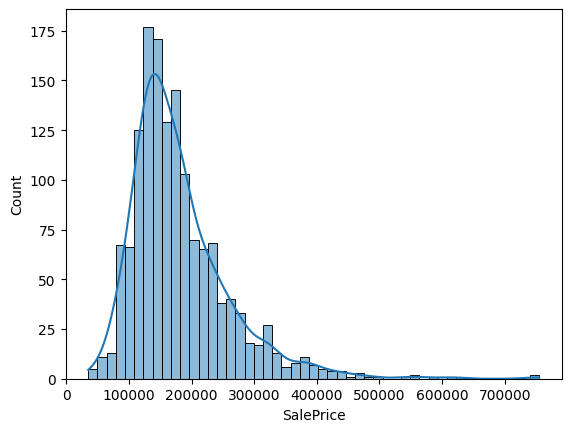

In [15]:
sns.histplot(df['SalePrice'], kde=True)
plt.show()

2.boxplot

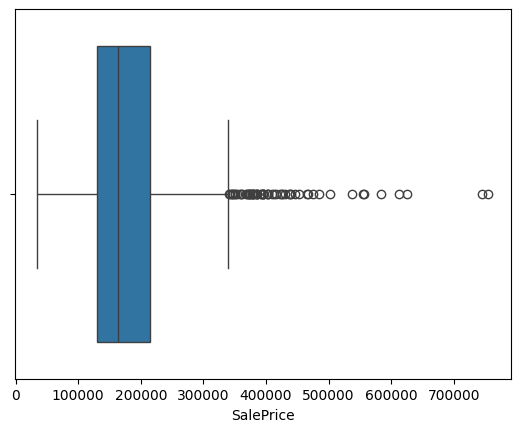

In [16]:
sns.boxplot(x=df['SalePrice'])
plt.show()

3. Log transformation

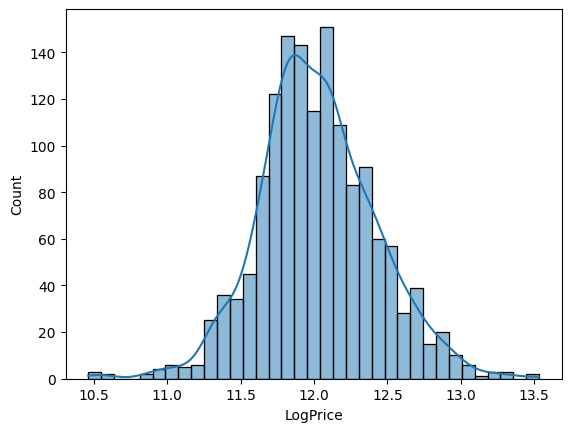

In [17]:
df['LogPrice'] = np.log(df['SalePrice'])

sns.histplot(df['LogPrice'], kde=True)
plt.show()

4. Quality vs price

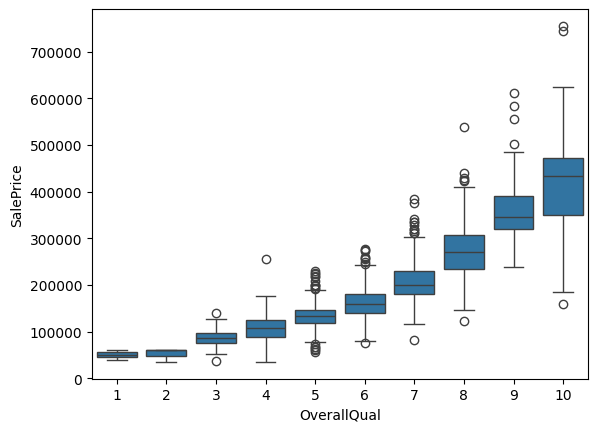

In [18]:
sns.boxplot(x='OverallQual', y='SalePrice', data=df)
plt.show()

5. Neighborhood vs price

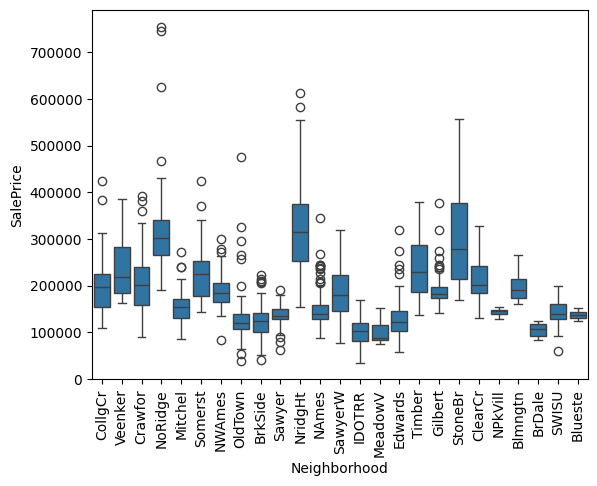

In [19]:
sns.boxplot(x='Neighborhood', y='SalePrice', data=df)
plt.xticks(rotation=90)
plt.show()

6. Countplot

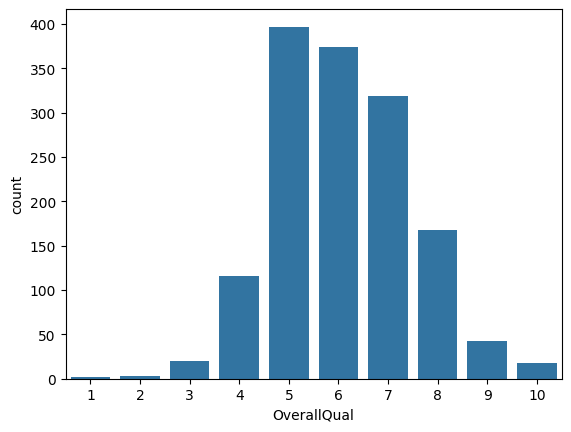

In [21]:
sns.countplot(x='OverallQual', data=df)
plt.show()

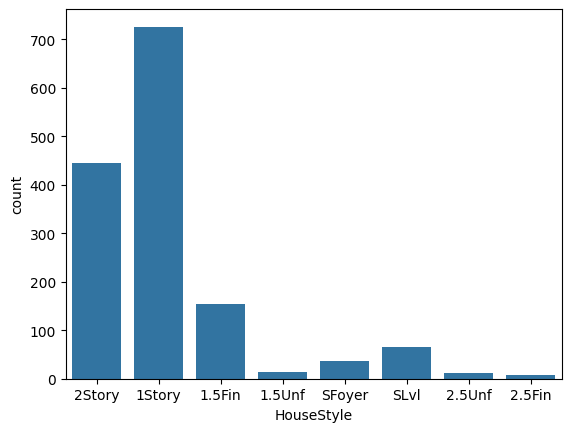

In [22]:
sns.countplot(x='HouseStyle', data=df)
plt.show()

### **Step 5:Correlation and covariance**

In [24]:
corr = df.corr(numeric_only=True)
print(corr)

                     Id  MSSubClass  LotFrontage   LotArea  OverallQual  \
Id             1.000000    0.011156    -0.010601 -0.033226    -0.028365   
MSSubClass     0.011156    1.000000    -0.386347 -0.139781     0.032628   
LotFrontage   -0.010601   -0.386347     1.000000  0.426095     0.251646   
LotArea       -0.033226   -0.139781     0.426095  1.000000     0.105806   
OverallQual   -0.028365    0.032628     0.251646  0.105806     1.000000   
OverallCond    0.012609   -0.059316    -0.059213 -0.005636    -0.091932   
YearBuilt     -0.012713    0.027850     0.123349  0.014228     0.572323   
YearRemodAdd  -0.021998    0.040581     0.088866  0.013788     0.550684   
MasVnrArea    -0.050298    0.022936     0.193458  0.104160     0.411876   
BsmtFinSF1    -0.005024   -0.069836     0.233633  0.214103     0.239666   
BsmtFinSF2    -0.005968   -0.065649     0.049900  0.111170    -0.059119   
BsmtUnfSF     -0.007940   -0.140759     0.132644 -0.002618     0.308159   
TotalBsmtSF   -0.015415  

In [25]:
cov = df.cov(numeric_only=True)
print(cov)

                          Id     MSSubClass    LotFrontage       LotArea  \
Id             177755.000000     198.968472    -108.390207 -1.398197e+05   
MSSubClass        198.968472    1789.338306    -404.439075 -5.901742e+04   
LotFrontage      -108.390207    -404.439075     589.749169  8.199814e+04   
LotArea       -139819.667238  -59017.418634   81998.138404  9.962565e+07   
OverallQual       -16.539068       1.908771       8.673047  1.460548e+03   
OverallCond         5.915696      -2.792117      -1.573935 -6.260287e+01   
YearBuilt        -161.881768      35.581337      95.108483  4.289113e+03   
YearRemodAdd     -191.474297      35.439934      45.744675  2.841344e+03   
MasVnrArea      -3842.687941     175.837842     871.207424  1.884014e+05   
BsmtFinSF1       -966.102125   -1347.355751    2635.952669  9.746908e+05   
BsmtFinSF2       -405.884167    -447.979166     187.215374  1.790022e+05   
BsmtUnfSF       -1479.131254   -2630.967059    1445.358556 -1.154799e+04   
TotalBsmtSF 

In [26]:
print(corr['SalePrice'].sort_values(ascending=False).head(10))

SalePrice       1.000000
LogPrice        0.948374
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
Name: SalePrice, dtype: float64


### **Step 6: Scatterplot and pairplot**

1. Living area vs price

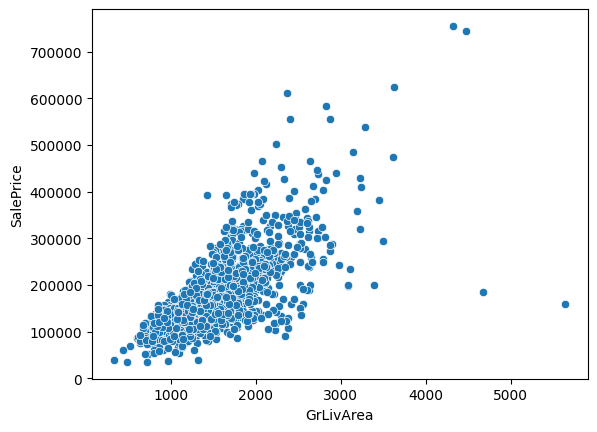

In [27]:
sns.scatterplot(x='GrLivArea', y='SalePrice', data=df)
plt.show()

2. Basement area vs price

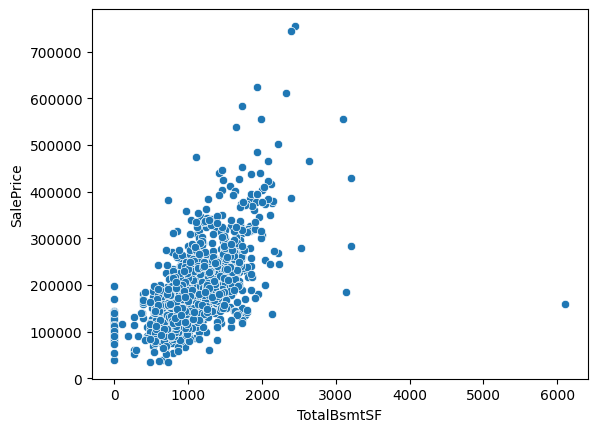

In [28]:
sns.scatterplot(x='TotalBsmtSF', y='SalePrice', data=df)
plt.show()

3. Year built vs price

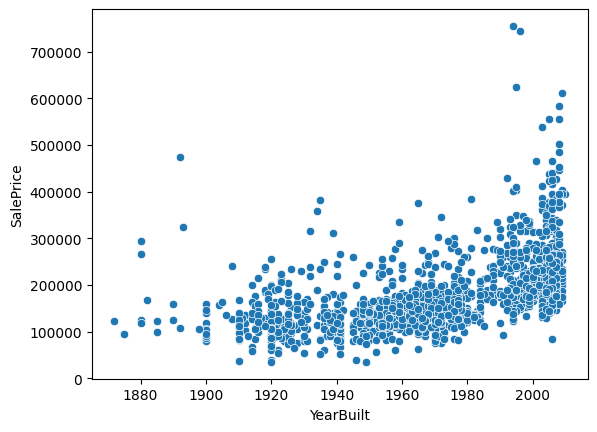

In [29]:
sns.scatterplot(x='YearBuilt', y='SalePrice', data=df)
plt.show()

4. Pairplot

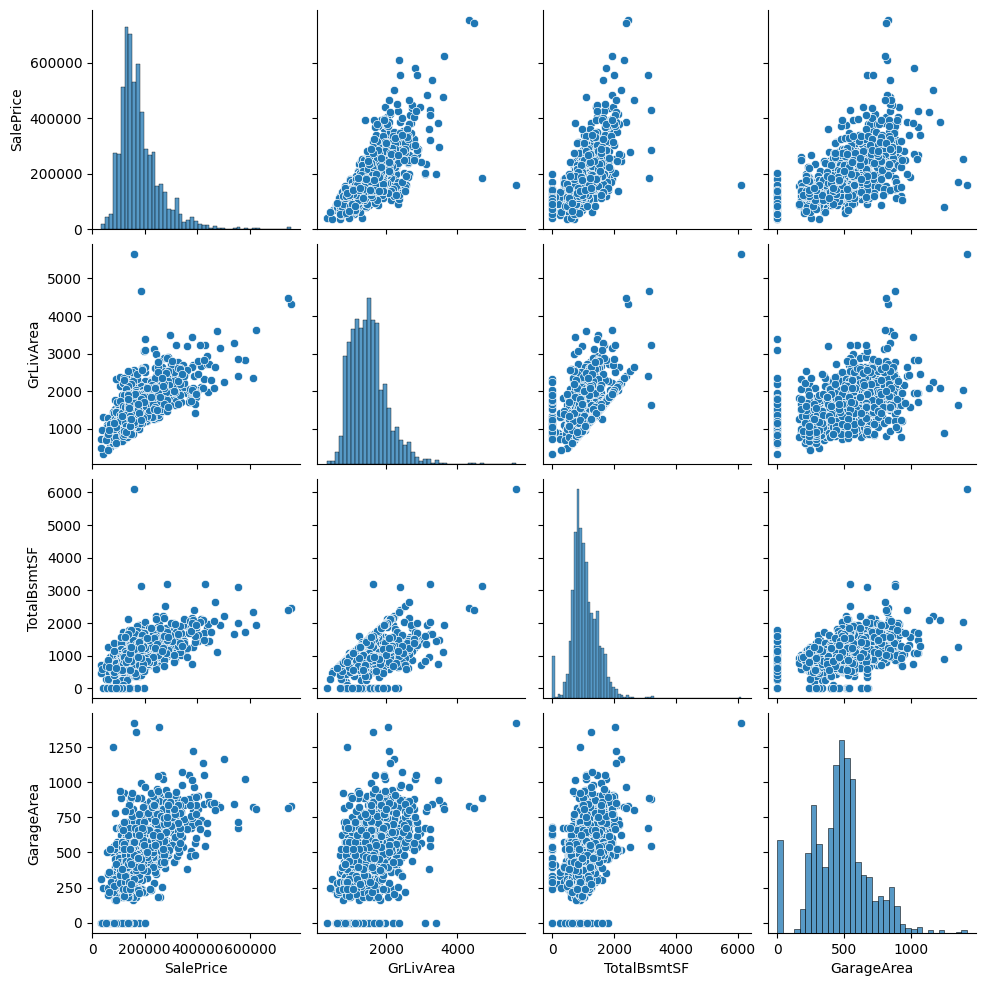

In [46]:
sns.pairplot(df[['SalePrice', 'GrLivArea','TotalBsmtSF', 'GarageArea']])

plt.show()

### **Step 7. Correlation heatmap**

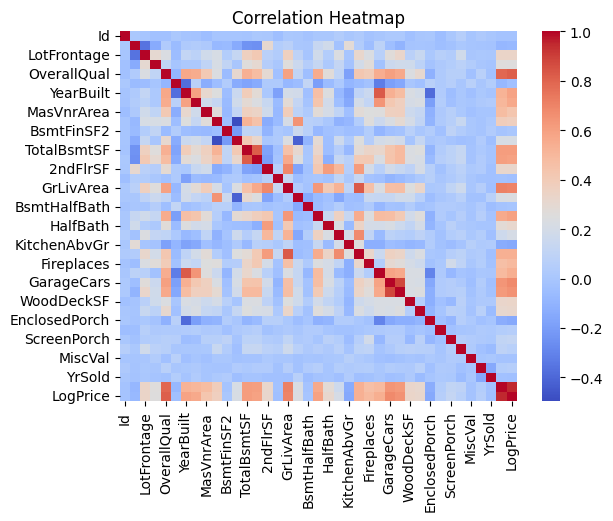

In [45]:
corr = df.corr(numeric_only=True)

sns.heatmap(corr, cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.show()

### **Step 8. Outlier detection**

1. IQR method

In [44]:
q1 = df['SalePrice'].quantile(0.25)
q3 = df['SalePrice'].quantile(0.75)

iqr = q3 - q1

low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

out = df[(df['SalePrice'] < low) |
         (df['SalePrice'] > high)]

print(out)

        Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
11      12          60       RL         85.0    11924   Pave  None      IR1   
53      54          20       RL         68.0    50271   Pave  None      IR1   
58      59          60       RL         66.0    13682   Pave  None      IR2   
112    113          60       RL         77.0     9965   Pave  None      Reg   
151    152          20       RL        107.0    13891   Pave  None      Reg   
...    ...         ...      ...          ...      ...    ...   ...      ...   
1268  1269          50       RL         69.0    14100   Pave  None      IR1   
1353  1354          50       RL         56.0    14720   Pave  None      IR1   
1373  1374          20       RL         69.0    11400   Pave  None      Reg   
1388  1389          20       RL         42.0    14892   Pave  None      IR1   
1437  1438          20       RL         96.0    12444   Pave  None      Reg   

     LandContour Utilities  ... PoolQC Fence MiscFe

2. Z-score method

In [43]:
z = (df['SalePrice'] - df['SalePrice'].mean()) / df['SalePrice'].std()

out = df[abs(z) > 3]

print(out)

        Id  MSSubClass MSZoning  LotFrontage  LotArea Street Alley LotShape  \
58      59          60       RL         66.0    13682   Pave  None      IR2   
178    179          20       RL         63.0    17423   Pave  None      IR1   
185    186          75       RM         90.0    22950   Pave  None      IR2   
349    350          60       RL         56.0    20431   Pave  None      IR2   
389    390          60       RL         96.0    12474   Pave  None      Reg   
440    441          20       RL        105.0    15431   Pave  None      Reg   
473    474          20       RL        110.0    14977   Pave  None      IR1   
496    497          20       RL         69.0    12692   Pave  None      IR1   
527    528          60       RL         67.0    14948   Pave  None      IR1   
591    592          60       RL         97.0    13478   Pave  None      IR1   
664    665          20       RL         49.0    20896   Pave  None      IR2   
691    692          60       RL        104.0    2153

3. Boxplot

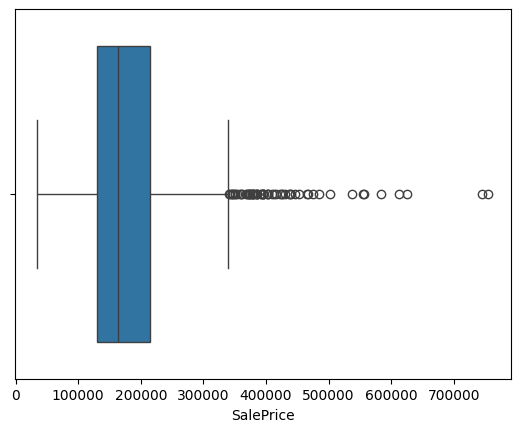

In [42]:
sns.boxplot(x=df['SalePrice'])
plt.show()

### **Step 9:Data cleaning**

1. Find duplicates

In [34]:
print(df.duplicated().sum())

0


2. Remove duplicates

In [36]:
df = df.drop_duplicates()

3. Fill missing values

In [38]:
df['PoolQC'] = df['PoolQC'].fillna('None')
df['Alley'] = df['Alley'].fillna('None')
df['Fence'] = df['Fence'].fillna('None')

4. Fill numerical missing values

In [39]:
df['LotFrontage'] = df['LotFrontage'].fillna(df['LotFrontage'].median())

5. Check incorrect values

In [40]:
print(df[df['YearBuilt'] > df['YrSold']])
print(df[df['GrLivArea'] < 0])

Empty DataFrame
Columns: [Id, MSSubClass, MSZoning, LotFrontage, LotArea, Street, Alley, LotShape, LandContour, Utilities, LotConfig, LandSlope, Neighborhood, Condition1, Condition2, BldgType, HouseStyle, OverallQual, OverallCond, YearBuilt, YearRemodAdd, RoofStyle, RoofMatl, Exterior1st, Exterior2nd, MasVnrType, MasVnrArea, ExterQual, ExterCond, Foundation, BsmtQual, BsmtCond, BsmtExposure, BsmtFinType1, BsmtFinSF1, BsmtFinType2, BsmtFinSF2, BsmtUnfSF, TotalBsmtSF, Heating, HeatingQC, CentralAir, Electrical, 1stFlrSF, 2ndFlrSF, LowQualFinSF, GrLivArea, BsmtFullBath, BsmtHalfBath, FullBath, HalfBath, BedroomAbvGr, KitchenAbvGr, KitchenQual, TotRmsAbvGrd, Functional, Fireplaces, FireplaceQu, GarageType, GarageYrBlt, GarageFinish, GarageCars, GarageArea, GarageQual, GarageCond, PavedDrive, WoodDeckSF, OpenPorchSF, EnclosedPorch, 3SsnPorch, ScreenPorch, PoolArea, PoolQC, Fence, MiscFeature, MiscVal, MoSold, YrSold, SaleType, SaleCondition, SalePrice, LogPrice]
Index: []

[0 rows x 82 colu

### **Step 10: Final dashboard**

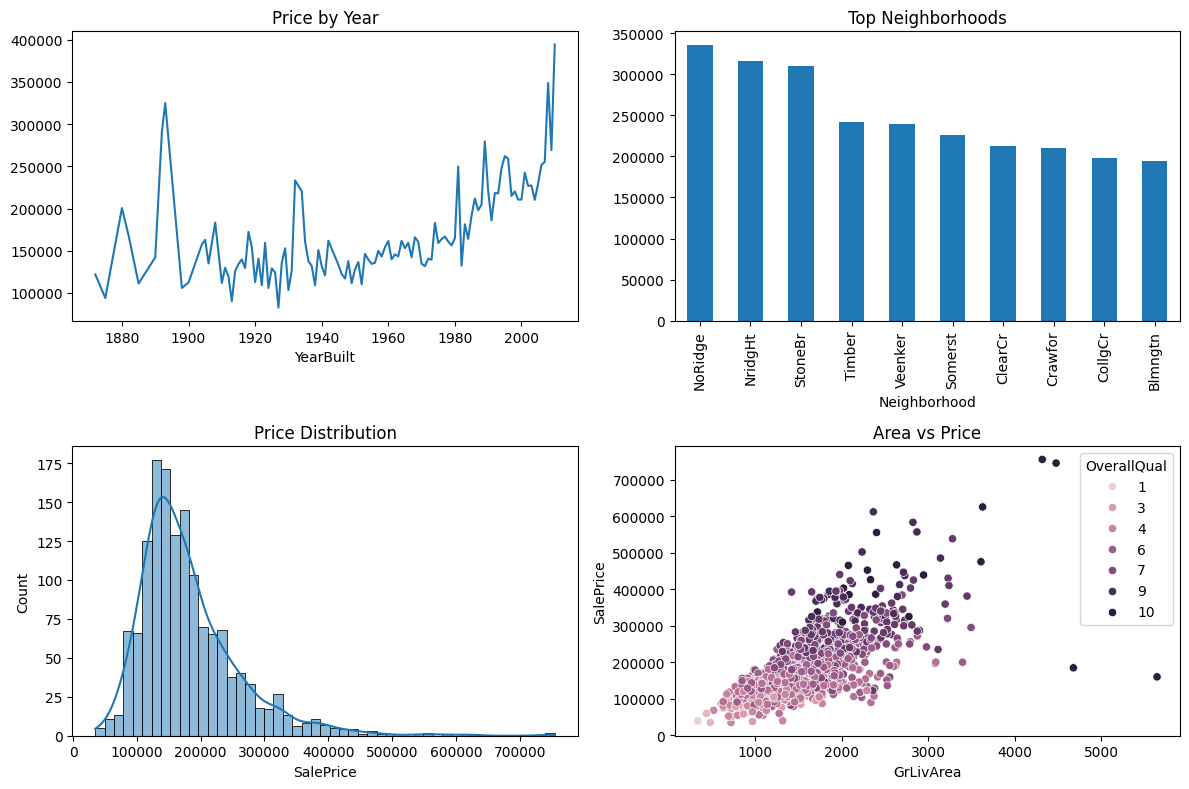

In [41]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
df.groupby('YearBuilt')['SalePrice'].mean().plot()
plt.title("Price by Year")

plt.subplot(2, 2, 2)
df.groupby('Neighborhood')['SalePrice'].mean().nlargest(10).plot(kind='bar')
plt.title("Top Neighborhoods")

plt.subplot(2, 2, 3)
sns.histplot(df['SalePrice'], kde=True)
plt.title("Price Distribution")

plt.subplot(2, 2, 4)
sns.scatterplot(x='GrLivArea', y='SalePrice', hue='OverallQual', data=df)
plt.title("Area vs Price")

plt.tight_layout()
plt.savefig("eda_dashboard.png")
plt.show()



 ### **Conclusion – Insights and Limitations**
 Insight
1. House Prices: Most house prices are concentrated in a particular range, while a few houses have very high prices.
2. Overall Quality: Houses with better overall quality generally have higher prices.
3. Living Area: Larger houses usually have higher selling prices.
4. Neighborhood: House prices are different in different neighbourhoods.
5. Correlation: Overall quality and living area are among the features strongly related to house prices.
6. Outliers: Some houses have unusually large areas but comparatively low prices.
7. Missing Values: Some missing values mean that a house does not have that particular feature.

 Limitations
1. Limited Dataset: The analysis uses only the Ames Housing dataset.
2. Missing Data: Some columns contain missing values.
3. Outliers: Unusual values may affect the analysis results.
4. Limited Features: All factors affecting house prices may not be available in the dataset.
5. No Prediction: This project only performs data analysis and does not predict future house prices.
6. Data Accuracy: Incorrect or incomplete data may affect the final results.